<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/BAB13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!tar -xzf flower_photos.tgz

In [3]:
import os
import shutil
import random

# Path sumber dan tujuan
SOURCE_DIR = "/content/flower_photos"
TRAIN_DIR = "/content/dataset/train"
VAL_DIR = "/content/dataset/val"
VAL_RATIO = 0.2  # 20% untuk validasi

random.seed(42)  # Agar hasil konsisten

# Hapus folder lama jika ada
if os.path.exists("/content/dataset"):
    shutil.rmtree("/content/dataset")

# Buat folder train dan val
os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(VAL_DIR, exist_ok=True)

# Loop setiap kelas (subfolder)
for class_name in os.listdir(SOURCE_DIR):
    class_path = os.path.join(SOURCE_DIR, class_name)
    if not os.path.isdir(class_path):
        continue

    # Buat subfolder kelas di train dan val
    os.makedirs(os.path.join(TRAIN_DIR, class_name), exist_ok=True)
    os.makedirs(os.path.join(VAL_DIR, class_name), exist_ok=True)

    # Ambil semua file gambar
    files = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(files)

    # Split
    split_idx = int(len(files) * (1 - VAL_RATIO))
    train_files = files[:split_idx]
    val_files = files[split_idx:]

    # Copy file
    for f in train_files:
        shutil.copy(os.path.join(class_path, f), os.path.join(TRAIN_DIR, class_name, f))
    for f in val_files:
        shutil.copy(os.path.join(class_path, f), os.path.join(VAL_DIR, class_name, f))

    print(f"{class_name}: {len(train_files)} train, {len(val_files)} val")

print("\n✅ Pembagian dataset selesai!")

sunflowers: 559 train, 140 val
roses: 512 train, 129 val
daisy: 506 train, 127 val
tulips: 639 train, 160 val
dandelion: 718 train, 180 val

✅ Pembagian dataset selesai!


In [4]:
!echo "=== TRAIN ===" && ls /content/dataset/train/
!echo "=== VAL ===" && ls /content/dataset/val/

=== TRAIN ===
daisy  dandelion  roses  sunflowers  tulips
=== VAL ===
daisy  dandelion  roses  sunflowers  tulips


In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

In [8]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    "/content/dataset/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = keras.utils.image_dataset_from_directory(
    "/content/dataset/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

jumlah_kelas = len(train_ds.class_names)
print(f"Jumlah kelas: {jumlah_kelas}")
print(f"Nama kelas: {train_ds.class_names}")

Found 2934 files belonging to 5 classes.
Found 736 files belonging to 5 classes.
Jumlah kelas: 5
Nama kelas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [9]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))


In [10]:
base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 767ms/step - accuracy: 0.7856 - loss: 0.6054 - val_accuracy: 0.8832 - val_loss: 0.3462
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 79s 858ms/step - accuracy: 0.8957 - loss: 0.2800 - val_accuracy: 0.8791 - val_loss: 0.3454
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 792ms/step - accuracy: 0.9325 - loss: 0.1903 - val_accuracy: 0.8886 - val_loss: 0.3302
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 70s 754ms/step - accuracy: 0.9550 - loss: 0.1302 - val_accuracy: 0.8872 - val_loss: 0.3382
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 69s 754ms/step - accuracy: 0.9693 - loss: 0.1000 - val_accuracy: 0.8832 - val_loss: 0.3541
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 822ms/step - accuracy: 0.9782 - loss: 0.0730 - val_accuracy: 0.8886 - val_loss: 0.3450
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 68s 743ms/step - accuracy: 0.9833 - loss: 0.0551 - val_accuracy: 0.8927 - val_loss: 0.3624
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 92s 841ms/step - accuracy: 0.9881 - loss: 0.0417 - val_accu

23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 631ms/step - accuracy: 0.8927 - loss: 0.4477
Akurasi Validasi: 0.893


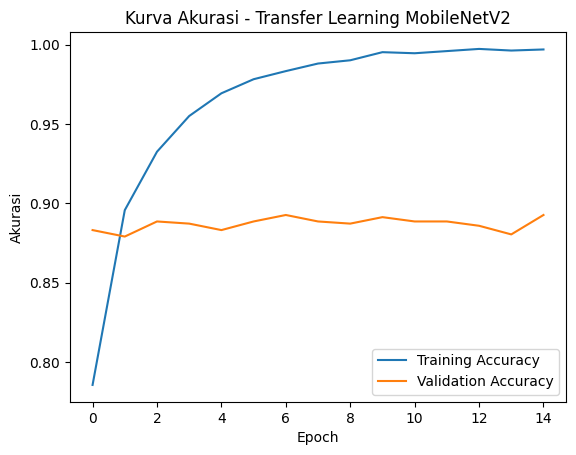

In [11]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc:.3f}")

# ============================================
# Praktikum 13.6 - Visualisasi
# ============================================
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend()
plt.show()